# ¿Funcionó la campaña? Evaluación de una campaña de email marketing

**Pregunta de negocio:** una tienda envió dos campañas de email (una con productos de hombre y otra de mujer) y dejó un grupo sin email como control. ¿Las campañas aumentaron de verdad las visitas, las compras y las ventas? ¿Fueron rentables? ¿A qué clientes conviene enviarles el email la próxima vez?

**Datos:** [Kevin Hillstrom: MineThatData E-Mail Analytics Challenge (2008)](https://blog.minethatdata.com/2008/03/minethatdata-e-mail-analytics-and-data.html). 64.000 clientes asignados **al azar** a tres grupos, con su comportamiento durante las dos semanas siguientes. Al ser un experimento aleatorio, las diferencias entre grupos se pueden atribuir a la campaña.

**Contenido**
1. Carga de datos
2. Verificar que los grupos son comparables
3. Resultados por grupo
4. ¿Las diferencias son reales? Pruebas estadísticas
5. Ventas incrementales y rentabilidad
6. ¿A quién le funciona mejor? Efecto por segmento
7. Modelo de uplift para elegir a quién enviar

In [1]:
import io
import gzip
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

PALETA = ["#6B2D8C", "#7A1F3D", "#B23A6A", "#D9C2E8", "#3E2447"]
COLORES_GRUPO = {"Sin email": "#9A8AA3", "Email hombre": PALETA[0], "Email mujer": PALETA[1]}
sns.set_theme(style="whitegrid", palette=PALETA)
RANDOM_STATE = 42

DATA_DIR = Path("data/raw")
OUT_DIR = Path("outputs")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

## 1. Carga de datos
El notebook descarga el archivo la primera vez. Si la descarga falla, busca "Hillstrom MineThatData E-Mail Analytics csv", descárgalo y guárdalo como `data/raw/hillstrom.csv`.

In [2]:
CSV = DATA_DIR / "hillstrom.csv"
FUENTES = [
    "http://www.minethatdata.com/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv",
    "https://hillstorm1.s3.us-east-2.amazonaws.com/hillstorm_no_indices.csv.gz",
]


def descargar_datos():
    if CSV.exists():
        return
    for url in FUENTES:
        try:
            print("Descargando desde", url)
            with urllib.request.urlopen(url, timeout=60) as r:
                contenido = r.read()
            if url.endswith(".gz"):
                contenido = gzip.decompress(contenido)
            pd.read_csv(io.BytesIO(contenido), nrows=5)  # comprueba que es un CSV válido
            CSV.write_bytes(contenido)
            return
        except Exception as e:
            print("  No se pudo:", e)
    raise FileNotFoundError(f"No se pudo descargar el dataset. Guárdalo manualmente en {CSV.resolve()}")


descargar_datos()
df = pd.read_csv(CSV)
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]

df["grupo"] = df["segment"].map({
    "No E-Mail": "Sin email",
    "Mens E-Mail": "Email hombre",
    "Womens E-Mail": "Email mujer",
})
ORDEN = ["Sin email", "Email hombre", "Email mujer"]
print(df.shape)
df.head()

Descargando desde http://www.minethatdata.com/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv
(64000, 13)


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend,grupo
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0,Email mujer
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0,Sin email
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0,Email mujer
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0,Email hombre
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0,Email mujer


**Variables**
- `recency`: meses desde la última compra · `history`: gasto del último año · `history_segment`: tramo de gasto
- `mens` / `womens`: compró productos de hombre / mujer el último año
- `zip_code`: Urban, Suburban o Rural · `newbie`: cliente nuevo (último año) · `channel`: canal por el que compró (Phone, Web, Multichannel)
- **Resultados** (dos semanas después): `visit` (visitó la web), `conversion` (compró), `spend` (monto gastado)

## 2. Verificar que los grupos son comparables
Antes de comparar resultados hay que confirmar que la asignación al azar funcionó: los tres grupos deben ser parecidos **antes** de la campaña.

In [3]:
balance = df.groupby("grupo").agg(
    clientes=("visit", "size"),
    recencia_media=("recency", "mean"),
    gasto_previo_medio=("history", "mean"),
    pct_compro_hombre=("mens", "mean"),
    pct_compro_mujer=("womens", "mean"),
    pct_nuevos=("newbie", "mean"),
).loc[ORDEN]
balance.round(3)

,clientes,recencia_media,gasto_previo_medio,pct_compro_hombre,pct_compro_mujer,pct_nuevos
grupo,,,,,,
Sin email,21306,5.750,240.883,0.553,0.548,0.502
Email hombre,21307,5.774,242.836,0.551,0.551,0.502
Email mujer,21387,5.768,242.537,0.549,0.550,0.503


**Lectura:** los grupos tienen tamaños y perfiles casi idénticos, así que cualquier diferencia posterior se debe a la campaña y no a que un grupo tuviera "mejores" clientes.

## 3. Resultados por grupo

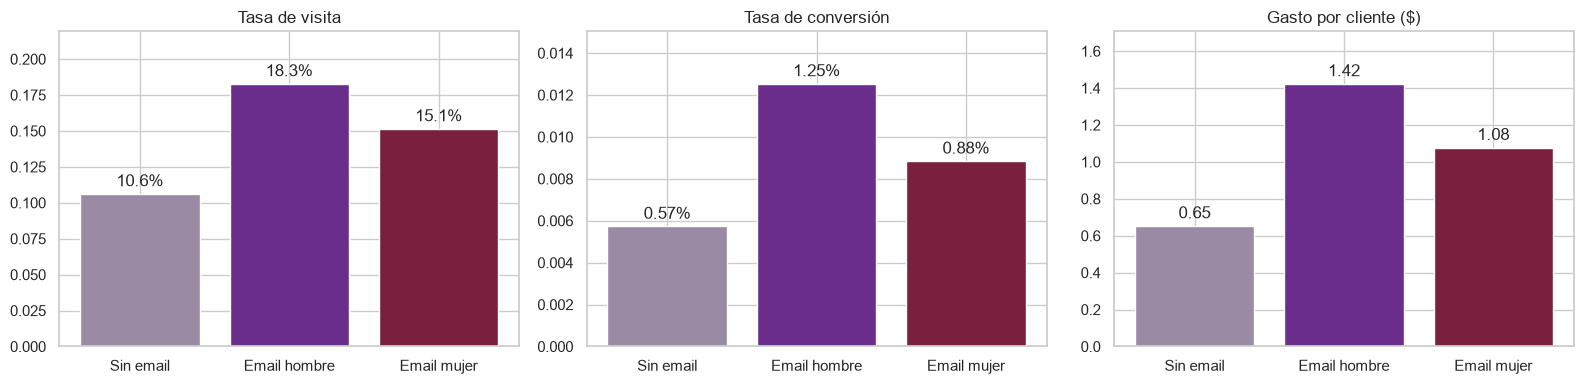

,clientes,tasa_visita,tasa_conversion,gasto_por_cliente,ventas_totales
grupo,,,,,
Sin email,21306,10.62%,0.57%,0.653,"13,908"
Email hombre,21307,18.28%,1.25%,1.423,"30,312"
Email mujer,21387,15.14%,0.88%,1.077,"23,038"


In [4]:
resultados = df.groupby("grupo").agg(
    clientes=("visit", "size"),
    tasa_visita=("visit", "mean"),
    tasa_conversion=("conversion", "mean"),
    gasto_por_cliente=("spend", "mean"),
    ventas_totales=("spend", "sum"),
).loc[ORDEN]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
metricas = [("tasa_visita", "Tasa de visita", "{:.1%}"),
            ("tasa_conversion", "Tasa de conversión", "{:.2%}"),
            ("gasto_por_cliente", "Gasto por cliente ($)", "{:.2f}")]
for ax, (col, titulo, fmt) in zip(axes, metricas):
    barras = ax.bar(resultados.index, resultados[col], color=[COLORES_GRUPO[g] for g in resultados.index])
    ax.bar_label(barras, labels=[fmt.format(v) for v in resultados[col]], padding=3)
    ax.set_title(titulo)
    ax.set_ylim(0, resultados[col].max() * 1.2)
plt.tight_layout()
plt.show()

resultados.style.format({"tasa_visita": "{:.2%}", "tasa_conversion": "{:.2%}",
                         "gasto_por_cliente": "{:.3f}", "ventas_totales": "{:,.0f}"})

## 4. ¿Las diferencias son reales?
Comparamos cada campaña contra el grupo sin email:
- **Visita y conversión:** prueba z de diferencia de proporciones.
- **Gasto por cliente:** prueba t de Welch (el gasto tiene muchos ceros y valores extremos, por eso también damos un intervalo bootstrap).

Una diferencia es estadísticamente significativa si el valor p es menor que 0,05.

In [5]:
def prueba_proporciones(x_trat, x_ctrl):
    p1, p0 = x_trat.mean(), x_ctrl.mean()
    n1, n0 = len(x_trat), len(x_ctrl)
    p = (x_trat.sum() + x_ctrl.sum()) / (n1 + n0)
    z = (p1 - p0) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n0))
    valor_p = 2 * (1 - stats.norm.cdf(abs(z)))
    ee = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
    return p1 - p0, (p1 - p0 - 1.96 * ee, p1 - p0 + 1.96 * ee), valor_p


def bootstrap_diferencia(x_trat, x_ctrl, n=2000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    a, b = np.asarray(x_trat), np.asarray(x_ctrl)
    difs = [rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(n)]
    return np.percentile(difs, [2.5, 97.5])


control = df[df["grupo"] == "Sin email"]
filas = []
for campana in ["Email hombre", "Email mujer"]:
    trat = df[df["grupo"] == campana]
    for col, nombre in [("visit", "Visita"), ("conversion", "Conversión")]:
        dif, ic, p = prueba_proporciones(trat[col], control[col])
        filas.append({"Campaña": campana, "Métrica": nombre, "Diferencia": dif,
                      "IC 95%": f"[{ic[0]:+.2%}, {ic[1]:+.2%}]", "Aumento relativo": dif / control[col].mean(),
                      "valor p": p})
    dif = trat["spend"].mean() - control["spend"].mean()
    ic = bootstrap_diferencia(trat["spend"], control["spend"])
    p = stats.ttest_ind(trat["spend"], control["spend"], equal_var=False).pvalue
    filas.append({"Campaña": campana, "Métrica": "Gasto por cliente ($)", "Diferencia": dif,
                  "IC 95%": f"[{ic[0]:+.3f}, {ic[1]:+.3f}]", "Aumento relativo": dif / control["spend"].mean(),
                  "valor p": p})

pruebas = pd.DataFrame(filas)
pruebas["¿Significativa?"] = np.where(pruebas["valor p"] < 0.05, "Sí", "No")
pruebas.style.format({"Diferencia": "{:+.4f}", "Aumento relativo": "{:+.0%}", "valor p": "{:.4f}"})

,Campaña,Métrica,Diferencia,IC 95%,Aumento relativo,valor p,¿Significativa?
0,Email hombre,Visita,+0.0766,"[+7.00%, +8.32%]",+72%,0.0000,Sí
1,Email hombre,Conversión,+0.0068,"[+0.50%, +0.86%]",+119%,0.0000,Sí
2,Email hombre,Gasto por cliente ($),+0.7698,"[+0.484, +1.052]",+118%,0.0000,Sí
3,Email mujer,Visita,+0.0452,"[+3.89%, +5.16%]",+43%,0.0000,Sí
4,Email mujer,Conversión,+0.0031,"[+0.15%, +0.47%]",+54%,0.0002,Sí
5,Email mujer,Gasto por cliente ($),+0.4244,"[+0.152, +0.686]",+65%,0.0011,Sí


## 5. Ventas incrementales y rentabilidad
Las **ventas incrementales** son las que no habrían ocurrido sin el email: (gasto por cliente con email − gasto por cliente sin email) × clientes que recibieron el email.

Supuestos **ilustrativos** (ajústalos a cada negocio): enviar un email cuesta 0,10 $ y el margen bruto sobre las ventas es del 30 %.

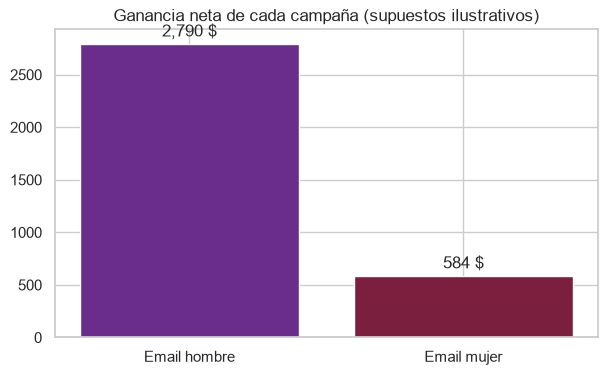

,Emails enviados,Ventas incrementales,Costo de envío,Ganancia neta,ROI
Campaña,,,,,
Email hombre,"21,307","16,403","2,131","2,790",131%
Email mujer,"21,387","9,077","2,139",584,27%


In [6]:
COSTO_EMAIL = 0.10   # supuesto ilustrativo
MARGEN = 0.30        # supuesto ilustrativo

gasto_control = control["spend"].mean()
rent = []
for campana in ["Email hombre", "Email mujer"]:
    trat = df[df["grupo"] == campana]
    incremental = (trat["spend"].mean() - gasto_control) * len(trat)
    costo = COSTO_EMAIL * len(trat)
    ganancia = incremental * MARGEN - costo
    rent.append({"Campaña": campana, "Emails enviados": len(trat), "Ventas incrementales": incremental,
                 "Costo de envío": costo, "Ganancia neta": ganancia, "ROI": ganancia / costo})

rentabilidad = pd.DataFrame(rent).set_index("Campaña")

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(rentabilidad.index, rentabilidad["Ganancia neta"],
                color=[COLORES_GRUPO[c] for c in rentabilidad.index])
ax.bar_label(barras, labels=[f"{v:,.0f} $" for v in rentabilidad["Ganancia neta"]], padding=3)
ax.axhline(0, color="gray", lw=1)
ax.set_title("Ganancia neta de cada campaña (supuestos ilustrativos)")
plt.show()

rentabilidad.style.format({"Emails enviados": "{:,.0f}", "Ventas incrementales": "{:,.0f}",
                           "Costo de envío": "{:,.0f}", "Ganancia neta": "{:,.0f}", "ROI": "{:.0%}"})

## 6. ¿A quién le funciona mejor? Efecto por segmento
El efecto promedio puede esconder diferencias: quizás la campaña funciona muy bien con un tipo de cliente y nada con otro. Calculamos el **aumento de conversión** (con email − sin email) en cada segmento.

Analizamos la campaña con mayor ganancia: Email hombre


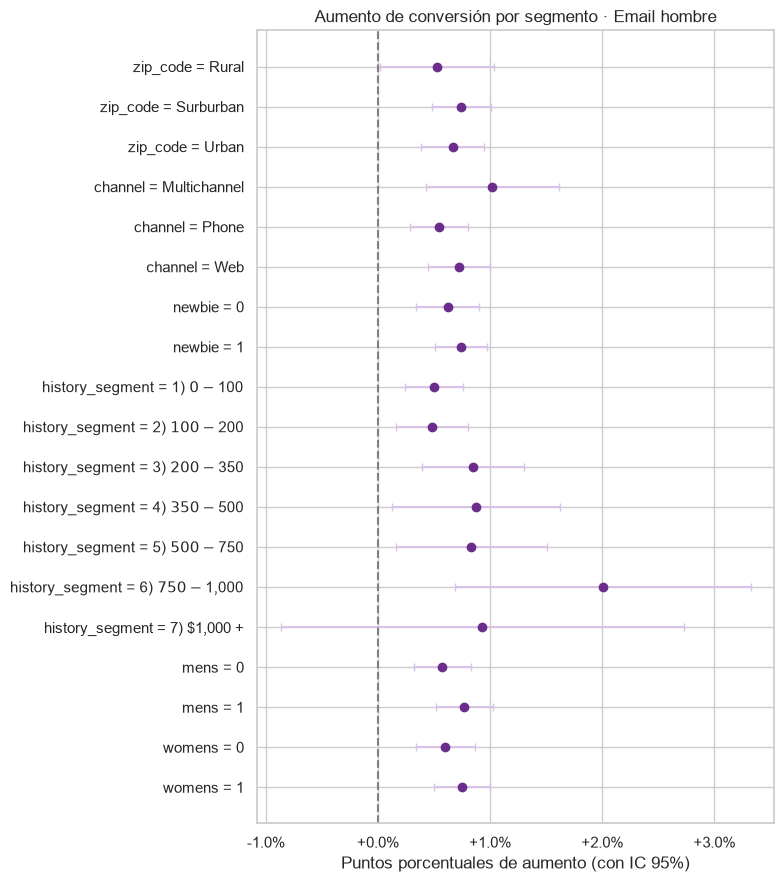

,variable,segmento,clientes,conv. sin email,conv. con email,aumento,valor p
0,zip_code,Rural,6382,0.83%,1.36%,+0.53%,0.043
1,zip_code,Surburban,19126,0.50%,1.24%,+0.74%,0.000
2,zip_code,Urban,17105,0.56%,1.23%,+0.66%,0.000
3,channel,Multichannel,5183,0.69%,1.71%,+1.02%,0.001
4,channel,Phone,18567,0.54%,1.08%,+0.55%,0.000
5,channel,Web,18863,0.58%,1.30%,+0.72%,0.000
6,newbie,0,21232,0.77%,1.39%,+0.62%,0.000
7,newbie,1,21381,0.37%,1.11%,+0.74%,0.000
8,history_segment,1) $0 - $100,15336,0.42%,0.92%,+0.50%,0.000
9,history_segment,2) $100 - $200,9527,0.41%,0.90%,+0.48%,0.003


In [7]:
def efecto_por_segmento(datos, campana, columna):
    filas = []
    for valor, sub in datos.groupby(columna):
        t = sub[sub["grupo"] == campana]
        c = sub[sub["grupo"] == "Sin email"]
        if len(t) < 100 or len(c) < 100:
            continue
        dif, ic, p = prueba_proporciones(t["conversion"], c["conversion"])
        filas.append({"variable": columna, "segmento": str(valor), "clientes": len(t) + len(c),
                      "conv. sin email": c["conversion"].mean(), "conv. con email": t["conversion"].mean(),
                      "aumento": dif, "ic_bajo": ic[0], "ic_alto": ic[1], "valor p": p})
    return filas


CAMPANA = rentabilidad["Ganancia neta"].idxmax()
print("Analizamos la campaña con mayor ganancia:", CAMPANA)

segmentos = pd.DataFrame(sum(
    (efecto_por_segmento(df, CAMPANA, col) for col in ["zip_code", "channel", "newbie", "history_segment", "mens", "womens"]),
    []
))

fig, ax = plt.subplots(figsize=(8, 0.42 * len(segmentos) + 1))
etiquetas = segmentos["variable"] + " = " + segmentos["segmento"]
y = np.arange(len(segmentos))
ax.errorbar(segmentos["aumento"], y,
            xerr=[segmentos["aumento"] - segmentos["ic_bajo"], segmentos["ic_alto"] - segmentos["aumento"]],
            fmt="o", color=PALETA[0], ecolor=PALETA[3], capsize=3)
ax.axvline(0, color="gray", ls="--")
ax.set_yticks(y, etiquetas)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.1%}"))
ax.set_title(f"Aumento de conversión por segmento · {CAMPANA}")
ax.set_xlabel("Puntos porcentuales de aumento (con IC 95%)")
plt.tight_layout()
plt.show()

segmentos.drop(columns=["ic_bajo", "ic_alto"]).style.format(
    {"conv. sin email": "{:.2%}", "conv. con email": "{:.2%}", "aumento": "{:+.2%}", "valor p": "{:.3f}"})

## 7. Modelo de uplift: ¿a quién enviar el email?
Un modelo de propensión normal predice quién va a comprar, pero muchos de esos clientes comprarían **aunque no reciban el email**. Un modelo de **uplift** estima cuánto *cambia* la probabilidad de compra gracias al email, para enviarlo solo a quien la campaña realmente influye.

Usamos el enfoque de **dos modelos** (T-learner): uno entrenado con los clientes que recibieron el email y otro con los que no. El uplift de cada cliente es la diferencia entre ambas predicciones.

In [8]:
VARIABLES = ["recency", "history", "mens", "womens", "zip_code", "newbie", "channel"]
CATEGORICAS = ["zip_code", "channel"]

datos = df[df["grupo"].isin(["Sin email", CAMPANA])].copy()
datos["tratado"] = (datos["grupo"] == CAMPANA).astype(int)
entreno, prueba = train_test_split(datos, test_size=0.3, stratify=datos[["tratado", "conversion"]],
                                   random_state=RANDOM_STATE)


def nuevo_modelo():
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS)],
                            remainder="passthrough")
    return Pipeline([("pre", pre), ("modelo", HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=200, max_depth=3, random_state=RANDOM_STATE))])


modelo_t = nuevo_modelo().fit(entreno.loc[entreno["tratado"] == 1, VARIABLES], entreno.loc[entreno["tratado"] == 1, "conversion"])
modelo_c = nuevo_modelo().fit(entreno.loc[entreno["tratado"] == 0, VARIABLES], entreno.loc[entreno["tratado"] == 0, "conversion"])

prueba["uplift"] = (modelo_t.predict_proba(prueba[VARIABLES])[:, 1]
                    - modelo_c.predict_proba(prueba[VARIABLES])[:, 1])

### Validación: aumento real por decil de uplift
Ordenamos a los clientes de prueba por el uplift estimado y, en cada decil, medimos el aumento **real** de conversión (tratados − control). Si el modelo funciona, los primeros deciles deben mostrar aumentos mayores.

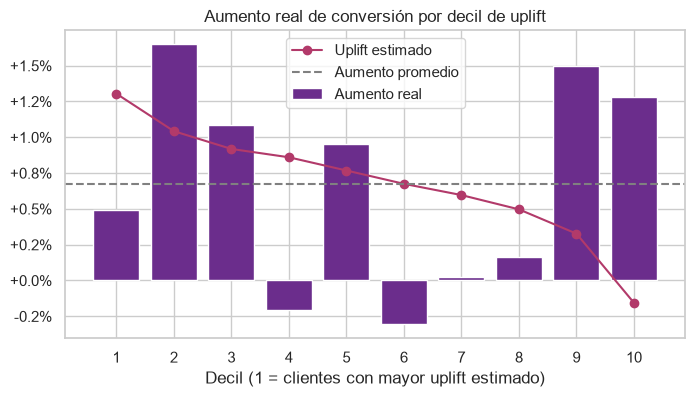

,clientes,uplift_estimado,aumento_real
decil,,,
1,1279.000000,+1.30%,+0.49%
2,1278.000000,+1.04%,+1.65%
3,1278.000000,+0.92%,+1.09%
4,1279.000000,+0.86%,-0.21%
5,1278.000000,+0.77%,+0.95%
6,1278.000000,+0.68%,-0.31%
7,1279.000000,+0.60%,+0.02%
8,1278.000000,+0.50%,+0.17%
9,1278.000000,+0.33%,+1.50%


In [9]:
prueba["decil"] = pd.qcut(prueba["uplift"].rank(method="first", ascending=False), 10, labels=range(1, 11))
por_decil = prueba.groupby("decil", observed=True).apply(
    lambda g: pd.Series({
        "clientes": len(g),
        "uplift_estimado": g["uplift"].mean(),
        "aumento_real": g.loc[g["tratado"] == 1, "conversion"].mean() - g.loc[g["tratado"] == 0, "conversion"].mean(),
    }), include_groups=False)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(por_decil.index.astype(str), por_decil["aumento_real"], color=PALETA[0], label="Aumento real")
ax.plot(por_decil.index.astype(str), por_decil["uplift_estimado"], color=PALETA[2], marker="o", label="Uplift estimado")
ax.axhline(prueba.loc[prueba["tratado"] == 1, "conversion"].mean() - prueba.loc[prueba["tratado"] == 0, "conversion"].mean(),
           color="gray", ls="--", label="Aumento promedio")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.1%}"))
ax.set_xlabel("Decil (1 = clientes con mayor uplift estimado)")
ax.set_title("Aumento real de conversión por decil de uplift")
ax.legend()
plt.show()
por_decil.style.format({"uplift_estimado": "{:+.2%}", "aumento_real": "{:+.2%}"})

### Curva de ganancia incremental
¿Cuántas compras adicionales conseguimos si enviamos el email solo a una parte de los clientes, empezando por los de mayor uplift? La comparamos con enviarlo al azar.

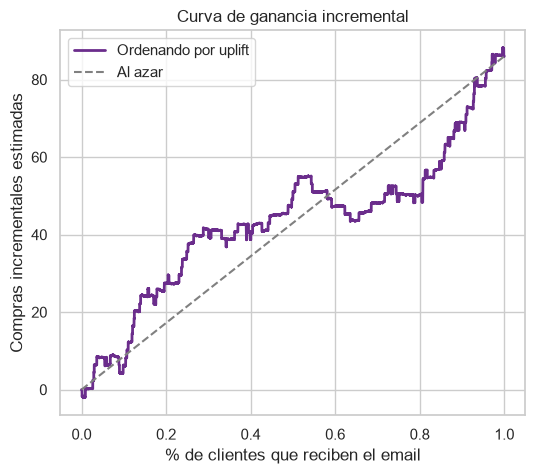

Enviando al 30% con mayor uplift se obtiene el 48% de las compras incrementales
Enviando al 50% con mayor uplift se obtiene el 59% de las compras incrementales


In [10]:
def curva_incremental(datos, columna_orden):
    d = datos.sort_values(columna_orden, ascending=False).reset_index(drop=True)
    t = d["tratado"].values
    y = d["conversion"].values
    nt, nc = np.cumsum(t), np.cumsum(1 - t)
    yt, yc = np.cumsum(y * t), np.cumsum(y * (1 - t))
    with np.errstate(divide="ignore", invalid="ignore"):
        incremental = (yt / nt - yc / nc) * (nt + nc)
    return np.arange(1, len(d) + 1) / len(d), np.nan_to_num(incremental)


x_modelo, inc_modelo = curva_incremental(prueba, "uplift")
total = inc_modelo[-1]

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(x_modelo, inc_modelo, color=PALETA[0], lw=2, label="Ordenando por uplift")
ax.plot([0, 1], [0, total], color="gray", ls="--", label="Al azar")
ax.set_xlabel("% de clientes que reciben el email")
ax.set_ylabel("Compras incrementales estimadas")
ax.set_title("Curva de ganancia incremental")
ax.legend()
plt.show()

for pct in (0.3, 0.5):
    i = int(pct * len(inc_modelo)) - 1
    print(f"Enviando al {pct:.0%} con mayor uplift se obtiene el {inc_modelo[i] / total:.0%} de las compras incrementales")

In [11]:
prueba[["recency", "history", "zip_code", "channel", "newbie", "uplift", "decil"]] \
    .sort_values("uplift", ascending=False).to_csv(OUT_DIR / "clientes_por_uplift.csv", index=False)
print("Exportado:", OUT_DIR / "clientes_por_uplift.csv")

Exportado: outputs\clientes_por_uplift.csv


## Conclusiones
- Al ser un experimento con grupo de control, se puede medir el **efecto causal** de cada campaña, no solo una correlación.
- Revisa la tabla de pruebas: indica qué campaña aumentó visitas, conversión y gasto de forma significativa, y en cuánto.
- Con los supuestos de costo y margen, la tabla de rentabilidad muestra cuál campaña genera ganancia neta.
- El efecto no es igual para todos: el análisis por segmento y el modelo de uplift permiten **enviar el email solo a los clientes en los que influye**, con menor costo para casi el mismo resultado.
- Siguiente paso: validar la selección por uplift en una nueva campaña, otra vez con grupo de control.